# Task 4 – End-to-End Machine Learning Project

**SWYNEX Technologies – Machine Learning Internship**

**Project Title:** Titanic Survival Prediction

**Objective:** To develop a complete machine learning project that predicts whether a passenger survived the Titanic disaster using passenger information.

**Dataset:** Titanic Dataset

**Algorithm:** Random Forest Classifier

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn

In [18]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [19]:
# Load the Titanic dataset

df = pd.read_csv(
    "https://raw.githubusercontent.com/hari-vasu-186/Swynex-Intern-/main/Task-4-End-to-End-project/data/Titanic-Dataset.csv"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [20]:
# Explore dataset information

print("Dataset Information:")
print("---------------------")

df.info()

print("\nMissing Values:")
print("---------------------")

print(df.isnull().sum())

print("\nStatistical Summary:")
print("---------------------")

df.describe()

Dataset Information:
---------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values:
---------------------
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket    

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [21]:
# Check missing values

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Total Missing Values: 866


In [22]:
# Handle missing values

# Fill missing Age with median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill missing Embarked with mode
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Fill missing Fare with median
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# Drop Cabin because it has too many missing values
df = df.drop(columns=['Cabin'])

# Remove unnecessary columns
df = df.drop(columns=['PassengerId', 'Name', 'Ticket'])

print("Data preprocessing completed!")
print("\nRemaining Missing Values:")
print(df.isnull().sum())

print("\nUpdated Dataset Shape:", df.shape)

Data preprocessing completed!

Remaining Missing Values:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

Updated Dataset Shape: (891, 8)


In [23]:
# Convert categorical columns into numerical values

df['Sex'] = df['Sex'].map({
    'male': 0,
    'female': 1
})

df = pd.get_dummies(
    df,
    columns=['Embarked'],
    dtype=int
)

print("Categorical encoding completed!")

print("\nUpdated Columns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Categorical encoding completed!

Updated Columns:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

First 5 Rows:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1


In [24]:
# Separate features and target

X = df.drop('Survived', axis=1)
y = df['Survived']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (891, 9)
Target shape: (891,)

Feature columns:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


In [25]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (712, 9)
Testing Features: (179, 9)
Training Target: (712,)
Testing Target: (179,)


In [26]:
# Create and train Random Forest model

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [27]:
# Make predictions

y_pred = model.predict(X_test)

print("Predictions completed successfully!")

print("\nFirst 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

Predictions completed successfully!

First 10 Actual Values:
[0 0 1 0 1 1 1 0 0 0]

First 10 Predicted Values:
[0 0 0 0 1 0 1 1 0 0]


In [28]:
# Evaluate model performance

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Random Forest Model Performance")
print("--------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

Random Forest Model Performance
--------------------------------
Accuracy : 0.8212
Precision: 0.8136
Recall   : 0.6957
F1 Score : 0.75


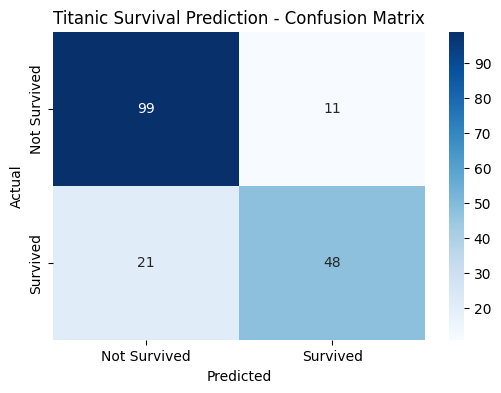

In [29]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.title('Titanic Survival Prediction - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [30]:
# Classification Report

print("Classification Report - Random Forest")
print("--------------------------------------")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Not Survived', 'Survived']
))

Classification Report - Random Forest
--------------------------------------
              precision    recall  f1-score   support

Not Survived       0.82      0.90      0.86       110
    Survived       0.81      0.70      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



In [31]:
# Predict survival for a new passenger

new_passenger = pd.DataFrame([{
    'Pclass': 3,
    'Sex': 1,
    'Age': 25,
    'SibSp': 0,
    'Parch': 0,
    'Fare': 20.0,
    'Embarked_C': 0,
    'Embarked_Q': 0,
    'Embarked_S': 1
}])

prediction = model.predict(new_passenger)

print("Titanic Passenger Survival Prediction")
print("-------------------------------------")

if prediction[0] == 1:
    print("Prediction: Passenger Survived")
else:
    print("Prediction: Passenger Did Not Survive")

Titanic Passenger Survival Prediction
-------------------------------------
Prediction: Passenger Did Not Survive


In [32]:
# Save the trained model

joblib.dump(model, 'random_forest_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [33]:
# Load the saved model

loaded_model = joblib.load('random_forest_model.pkl')

print("Model loaded successfully!")

# Test the loaded model
test_prediction = loaded_model.predict(new_passenger)

print("\nPrediction using loaded model:")

if test_prediction[0] == 1:
    print("Passenger Survived")
else:
    print("Passenger Did Not Survive")

Model loaded successfully!

Prediction using loaded model:
Passenger Did Not Survive


In [34]:
from google.colab import files

files.download('random_forest_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>